# 03 – Final evaluation on the held-out test set

**CT4101 Machine Learning Portfolio Project – Milestone 4 (Final Portfolio)**

**Question:** Based on a set of features describing a website's URL, domain and page behaviour, can a model determine
whether a site is phishing or legitimate, without missing many phishing sites?

This notebook is the last step of the workflow:
`data_baseline.ipynb` → `model_comparison.ipynb` → **`final_evaluation.ipynb`**.

Up to now, every decision used only the training set (80%). Here the held-out **test set (20%) is used for the first
and only time** to estimate how the chosen model performs on unseen data.

Contents:
1. Setup and data (same cleaning, split and folds as before)
2. Decisions fixed before looking at the test set
3. Refit the final models on the full training set
4. Choosing a decision threshold (training data only)
5. Test-set results
6. Test-set confusion matrices
7. Test-set error analysis
8. Final conclusion

## 1. Setup and data

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score, confusion_matrix, f1_score,
                             precision_recall_curve, precision_score, recall_score, roc_auc_score)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_predict, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

PROJECT_ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(PROJECT_ROOT))
from src.data import FEATURE_NAMES, TARGET_NAME, load_dataset

RANDOM_STATE = 42      # same seed as the earlier notebooks, so the split and folds are identical
TEST_SIZE = 0.20
N_FOLDS = 5
TARGET_RECALL = 0.97   # see Section 4
FIG_DIR = PROJECT_ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR = PROJECT_ROOT / "reports"
warnings.filterwarnings("ignore", category=FutureWarning)

In [2]:
raw = load_dataset()
data = raw.drop_duplicates().reset_index(drop=True)          # duplicates removed BEFORE splitting
X = data[FEATURE_NAMES]
y = (data[TARGET_NAME] == -1).astype(int).rename("is_phishing")   # 1 = phishing

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, stratify=y, random_state=RANDOM_STATE
)
outer_cv = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=RANDOM_STATE)
inner_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
print(f"Training set: {len(X_train)} rows   Test set: {len(X_test)} rows ({y_test.mean():.1%} phishing)")

Training set: 4679 rows   Test set: 1170 rows (51.6% phishing)


## 2. Decisions fixed before looking at the test set

To keep the test estimate honest, these were all decided from training-set results (Milestone 3) **before** this
notebook touches the test set, and the test results are not used to change any of them:

- **Final model: random forest** (300 trees, `max_depth` and `min_samples_leaf` chosen by grid search on the training
  set, exactly as in `model_comparison.ipynb`). It had the best cross-validated scores on every metric.
- **Logistic regression** is also reported, as the simpler and more interpretable runner-up, so the report can
  discuss the trade-off. It is *not* a second attempt at picking a winner.
- **Majority-class baseline**, for reference.
- **Decision threshold:** chosen from training-set out-of-fold predictions only (Section 4).

## 3. Refit the final models on the full training set

Same pipelines and grids as Milestone 3.

In [3]:
def make_pipeline(model):
    return Pipeline([("preprocess", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
                     ("model", model)])

rf_search = GridSearchCV(
    make_pipeline(RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1)),
    {"model__max_depth": [None, 15], "model__min_samples_leaf": [1, 3]},
    scoring="f1", cv=inner_cv, n_jobs=-1,
).fit(X_train, y_train)

lr_search = GridSearchCV(
    make_pipeline(LogisticRegression(max_iter=2000)),
    {"model__C": [0.01, 0.1, 1, 10]},
    scoring="f1", cv=inner_cv, n_jobs=-1,
).fit(X_train, y_train)

baseline = make_pipeline(DummyClassifier(strategy="most_frequent")).fit(X_train, y_train)

final_rf = rf_search.best_estimator_
final_lr = lr_search.best_estimator_
print("Random forest settings:      ", rf_search.best_params_)
print("Logistic regression settings:", lr_search.best_params_)

Random forest settings:       {'model__max_depth': 15, 'model__min_samples_leaf': 1}
Logistic regression settings: {'model__C': 1}


## 4. Choosing a decision threshold (training data only)

By default a classifier labels a site as phishing when its predicted probability is at least 0.5. For this problem a
missed phishing site is the more harmful error (Milestone 1), so it can make sense to **lower the threshold**: more
phishing sites are caught, at the cost of more false alarms.

**Rule (set in advance):** use the highest threshold that reaches a recall of at least **0.97** in the training
set's out-of-fold predictions. 0.97 is a judgement call: it roughly halves the missed phishing sites seen in
cross-validation while keeping precision above 0.9. The threshold is chosen without the test set; the test set is only
used afterwards to check whether it holds up.

In [4]:
oof_proba = cross_val_predict(final_rf, X_train, y_train, cv=outer_cv, method="predict_proba")[:, 1]

rows = []
for t in [0.5, 0.45, 0.4, 0.35, 0.3, 0.25]:
    pred = (oof_proba >= t).astype(int)
    rows.append({"threshold": t, "recall": recall_score(y_train, pred), "precision": precision_score(y_train, pred),
                 "f1": f1_score(y_train, pred), "false_alarms": int(((pred == 1) & (y_train == 0)).sum()),
                 "missed_phishing": int(((pred == 0) & (y_train == 1)).sum())})
pd.DataFrame(rows).round(3)

,threshold,recall,precision,f1,false_alarms,missed_phishing
0,0.50,0.945,0.955,0.950,108,132
1,0.45,0.956,0.947,0.951,130,107
2,0.40,0.961,0.937,0.949,155,95
3,0.35,0.968,0.926,0.946,188,78
4,0.30,0.977,0.914,0.944,223,56
5,0.25,0.984,0.897,0.939,273,38


Chosen threshold: 0.34


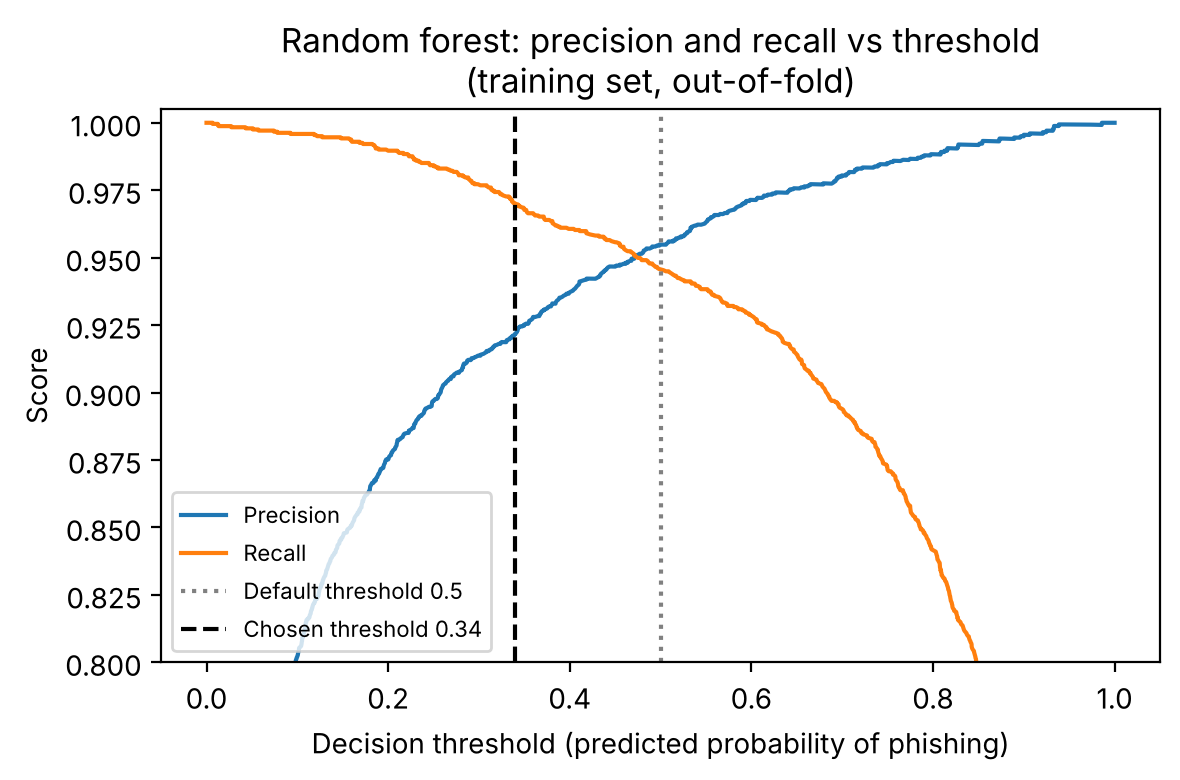

In [5]:
precision, recall, thresholds = precision_recall_curve(y_train, oof_proba)
THRESHOLD = round(float(thresholds[recall[:-1] >= TARGET_RECALL].max()), 2)
print(f"Chosen threshold: {THRESHOLD}")

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(thresholds, precision[:-1], label="Precision")
ax.plot(thresholds, recall[:-1], label="Recall")
ax.axvline(0.5, color="grey", ls=":", label="Default threshold 0.5")
ax.axvline(THRESHOLD, color="black", ls="--", label=f"Chosen threshold {THRESHOLD}")
ax.set_xlabel("Decision threshold (predicted probability of phishing)")
ax.set_ylabel("Score")
ax.set_ylim(0.8, 1.005)
ax.set_title("Random forest: precision and recall vs threshold\n(training set, out-of-fold)")
ax.legend(fontsize=8, loc="lower left")
plt.tight_layout()
plt.savefig(FIG_DIR / "threshold_choice.png", dpi=150)
plt.show()

## 5. Test-set results

The test set is used here for the first time.

In [6]:
def evaluate(name, proba, threshold):
    pred = (proba >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    return {"model": name, "threshold": threshold,
            "recall": recall_score(y_test, pred), "precision": precision_score(y_test, pred),
            "f1": f1_score(y_test, pred), "roc_auc": roc_auc_score(y_test, proba),
            "accuracy": accuracy_score(y_test, pred), "missed_phishing": fn, "false_alarms": fp}

rf_proba = final_rf.predict_proba(X_test)[:, 1]
lr_proba = final_lr.predict_proba(X_test)[:, 1]
base_proba = baseline.predict_proba(X_test)[:, 1]

test_results = pd.DataFrame([
    evaluate("Majority class (baseline)", base_proba, 0.5),
    evaluate("Logistic regression", lr_proba, 0.5),
    evaluate("Random forest", rf_proba, 0.5),
    evaluate(f"Random forest (threshold {THRESHOLD})", rf_proba, THRESHOLD),
]).set_index("model").round(3)
test_results.to_csv(RESULTS_DIR / "final_test_results.csv")
test_results

,threshold,recall,precision,f1,roc_auc,accuracy,missed_phishing,false_alarms
model,,,,,,,,
Majority class (baseline),0.50,1.000,0.516,0.681,0.500,0.516,0,566
Logistic regression,0.50,0.927,0.946,0.936,0.986,0.935,44,32
Random forest,0.50,0.932,0.962,0.947,0.991,0.946,41,22
Random forest (threshold 0.34),0.34,0.970,0.930,0.950,0.991,0.947,18,44


In [7]:
# Compare with the cross-validation estimates from Milestone 3 (training set)
cv_results = pd.read_csv(RESULTS_DIR / "model_comparison_cv_results.csv", index_col=0)
comparison = pd.DataFrame({
    "CV F1 (training)": cv_results.loc[["Logistic regression", "Random forest"], "f1"],
    "Test F1": test_results.loc[["Logistic regression", "Random forest"], "f1"],
    "CV recall (training)": cv_results.loc[["Logistic regression", "Random forest"], "recall"],
    "Test recall": test_results.loc[["Logistic regression", "Random forest"], "recall"],
})
comparison

,CV F1 (training),Test F1,CV recall (training),Test recall
Logistic regression,0.939 ± 0.005,0.936,0.930 ± 0.008,0.927
Random forest,0.951 ± 0.004,0.947,0.946 ± 0.011,0.932


**Reading the results.**
- The random forest's test scores are close to its cross-validation estimates (F1 0.947 vs 0.951; recall slightly
  lower at 0.932 vs 0.946; ROC-AUC ≈ 0.99), so the CV estimate was realistic and there is no sign of overfitting
  to the training data.
- The random forest stays ahead of logistic regression on the test set, as it was in cross-validation, though the gap
  is small (about one point of F1).
- **The chosen threshold holds up:** on the test set it raises recall to about the 0.97 target, more than halving the
  missed phishing sites, while F1 stays about the same. The cost is roughly twice as many false alarms.

## 6. Test-set confusion matrices

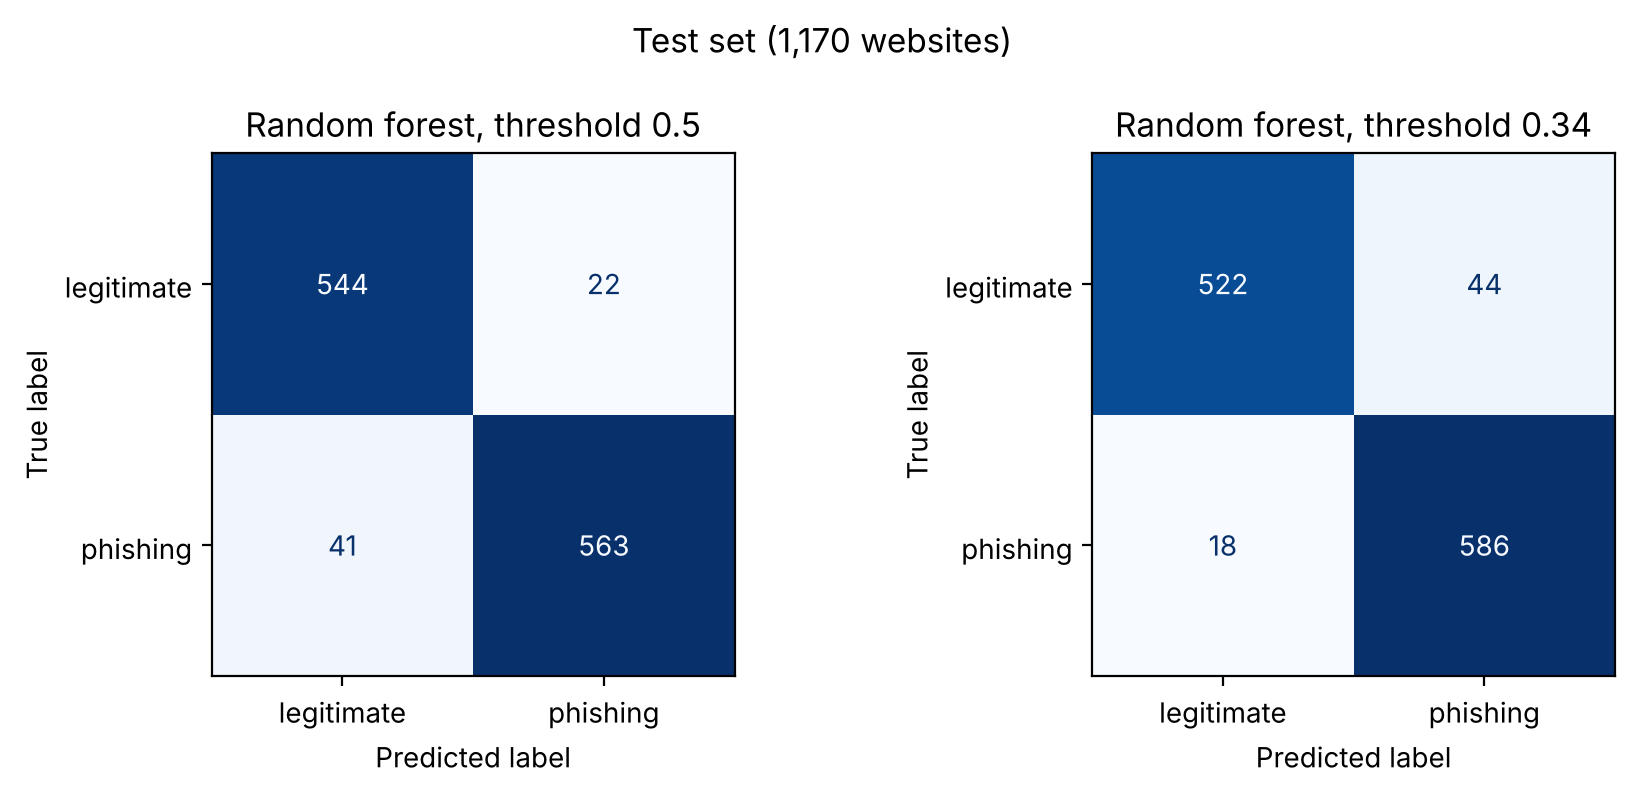

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
for ax, t in zip(axes, [0.5, THRESHOLD]):
    ConfusionMatrixDisplay.from_predictions(y_test, (rf_proba >= t).astype(int),
                                            display_labels=["legitimate", "phishing"],
                                            cmap="Blues", colorbar=False, ax=ax)
    ax.set_title(f"Random forest, threshold {t}")
plt.suptitle("Test set (1,170 websites)")
plt.tight_layout()
plt.savefig(FIG_DIR / "test_confusion_matrices.png", dpi=150)
plt.show()

## 7. Test-set error analysis

Does the main weakness found in cross-validation (missing phishing sites that have trusted HTTPS) also appear on unseen
data?

In [9]:
test_df = X_test.assign(actual=y_test, predicted=(rf_proba >= 0.5).astype(int),
                        predicted_low_t=(rf_proba >= THRESHOLD).astype(int))
phishing = test_df[test_df.actual == 1]

ssl_labels = {-1: "-1 (no/untrusted HTTPS)", 0: "0 (suspicious)", 1: "1 (trusted HTTPS)"}
recall_by_ssl = (phishing.groupby("ssl_final_state")
                 .agg(phishing_sites=("actual", "size"),
                      recall_at_0_5=("predicted", "mean"),
                      recall_at_chosen=("predicted_low_t", "mean"))
                 .rename(index=ssl_labels).round(3))
recall_by_ssl

,phishing_sites,recall_at_0_5,recall_at_chosen
ssl_final_state,,,
-1 (no/untrusted HTTPS),361,0.978,0.997
0 (suspicious),137,1.000,1.000
1 (trusted HTTPS),106,0.689,0.840


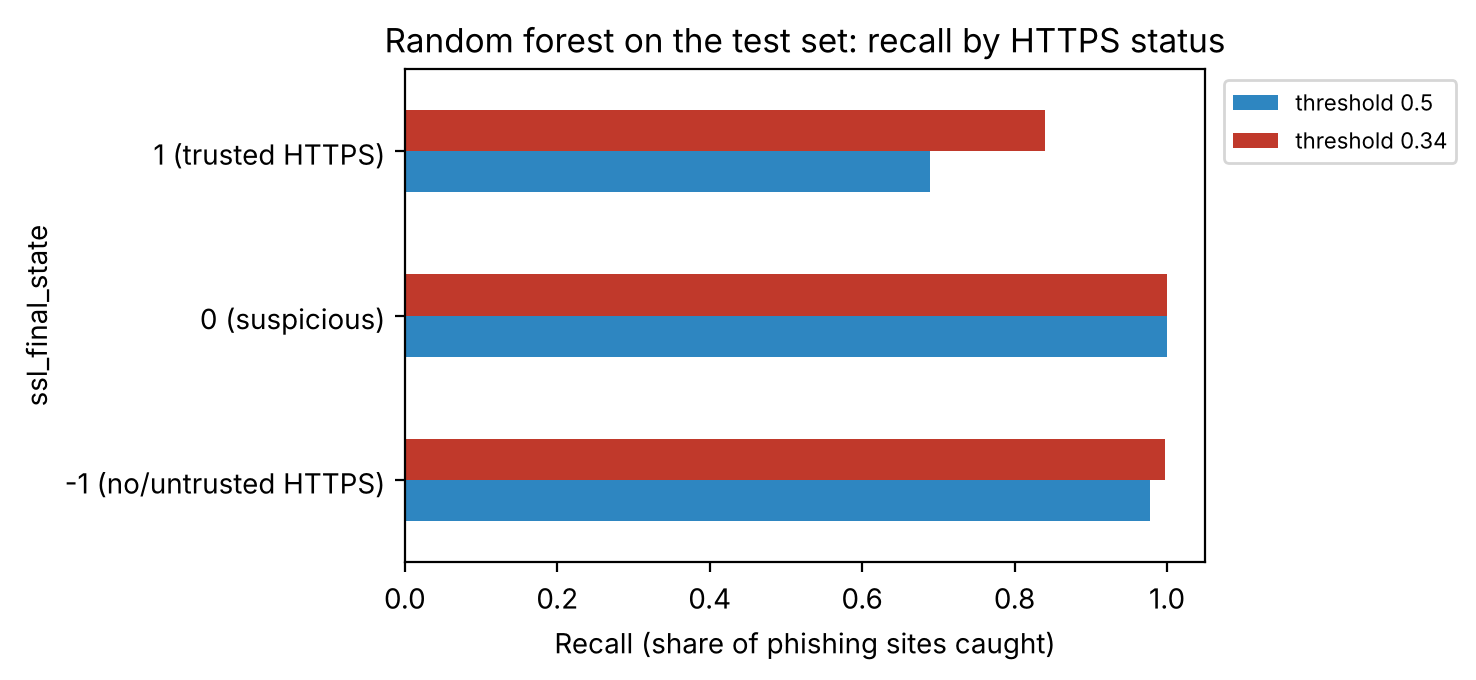

In [10]:
fig, ax = plt.subplots(figsize=(7.5, 3.5))
recall_by_ssl[["recall_at_0_5", "recall_at_chosen"]].plot.barh(
    ax=ax, color=["#2e86c1", "#c0392b"])
ax.set_xlabel("Recall (share of phishing sites caught)")
ax.set_ylabel("ssl_final_state")
ax.set_xlim(0, 1.05)
ax.legend(["threshold 0.5", f"threshold {THRESHOLD}"], fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1))
ax.set_title("Random forest on the test set: recall by HTTPS status")
plt.tight_layout()
plt.savefig(FIG_DIR / "test_recall_by_ssl.png", dpi=150)
plt.show()

In [11]:
errors = test_df[test_df.actual != test_df.predicted]
missed = errors[errors.actual == 1]
label_count = data.groupby(FEATURE_NAMES)[TARGET_NAME].nunique()
conflicting = label_count[label_count > 1].index
in_conflict = errors[FEATURE_NAMES].set_index(FEATURE_NAMES).index.isin(conflicting)

print(f"Test errors at threshold 0.5: {len(errors)} ({len(missed)} missed phishing, {len(errors) - len(missed)} false alarms)")
print(f"Missed phishing sites with trusted HTTPS (ssl_final_state = 1): {(missed.ssl_final_state == 1).sum()} of {len(missed)}")
print(f"Missed phishing sites with url_of_anchor = 0 (mixed links): {(missed.url_of_anchor == 0).sum()} of {len(missed)}")
print(f"Errors on feature patterns that appear with both labels: {in_conflict.sum()} of {len(errors)}")

Test errors at threshold 0.5: 63 (41 missed phishing, 22 false alarms)
Missed phishing sites with trusted HTTPS (ssl_final_state = 1): 33 of 41
Missed phishing sites with url_of_anchor = 0 (mixed links): 40 of 41
Errors on feature patterns that appear with both labels: 21 of 63


The same pattern appears on the test set. The model catches almost every phishing site **without** trusted HTTPS,
but only about **two in three** phishing sites **with** trusted HTTPS, and these make up most of the missed phishing
sites. Lowering the threshold helps most in exactly this group, but it remains the weakest. As before, about a third of
errors are on feature patterns that occur with both labels, which no model using these features can fully resolve.

This matters for real use: free HTTPS certificates have made trusted-HTTPS phishing sites much more common than when
this data was collected (2012–2015), so on current websites this weakness would probably affect a larger share of
phishing sites than it does here.

## 8. Final conclusion

**Answer to the question.** Yes, within this dataset: a random forest trained on the 30 coded URL, domain and page
features identifies phishing websites well on unseen data (test F1 ≈ 0.95, ROC-AUC ≈ 0.99, against F1 ≈ 0.68 and
ROC-AUC 0.5 for the majority-class baseline). With the decision threshold lowered to the value chosen on training
data, it catches about 97% of phishing sites, at the cost of wrongly flagging about 8% of legitimate sites (compared with
about 4% at the default threshold).

**Evidence.** The random forest was the best model in nested cross-validation on every metric, beat logistic
regression in all 5 folds, and its test results agree with the cross-validation estimate. Logistic regression is
only about one point of F1 behind and is easier to interpret, so it is a reasonable choice where explainability matters
more than a small gain in accuracy.

**Main limitation.** The model is weakest on phishing sites with trusted HTTPS (only about two thirds caught), the
kind of phishing that has become common since the data was collected. Together with the age of the data and the
pre-encoded features, this means the results describe this dataset rather than how the model would perform on
today's web, and the model should not be used as a stand-alone phishing filter without evaluation on recent data.
The report discusses limitations and responsible-use issues in more detail.